# `Comportamento das MLPs: Regressão (seno + Concrete Compressive Strength)`



- **V1: Capacidade**: 2 x 8 x 32 neurônios (seno)
- **V2: Ativação**: sigmoid x tanh x ReLU (seno)
- **V3: Generalização/Ruído**: sem ruído x com ruído N(0, 0,1) (seno), + **V3b** (bônus): capacidade x ruído
- **V4: Escala**: atributos brutos x padronizados (Concrete)
- **Extensões opcionais**: capacidade no Concrete; taxa de aprendizado no seno

Baseline: 1 camada oculta, 8 neurônios, tanh, Adam (lr=0,01), split 70/15/15, 3 sementes por configuração, early stopping manual por validação.


### `Dupla:`

Anysabele de Paula Barbosa Santos

Millena Ferreira Marçal das Neves

In [ ]:
%matplotlib inline
import warnings, time, io, os
from copy import deepcopy
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.exceptions import ConvergenceWarning
from matplotlib import MatplotlibDeprecationWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=MatplotlibDeprecationWarning)

RANDOM_SEEDS = [0, 1, 2]
SPLIT_SEED = 42
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Bibliotecas carregadas. Sementes:", RANDOM_SEEDS)

Bibliotecas carregadas. Sementes: [0, 1, 2]


### `Dados`

Duas fontes:
- **Seno sintético** `y = sin(x)`, gerado em código.
- **Concrete Compressive Strength** (UCI, Yeh 1998, DOI: 10.24432/C5PK67, CC BY 4.0) 1.030 amostras, 8 atributos, 1 alvo (resistência em MPa), sem valores ausentes.

In [ ]:
def make_sine_data(n_samples=240, noise_std=0.0, x_range=(-2*np.pi, 2*np.pi), seed=0):
    """y = sin(x) [+ ruido gaussiano opcional]. O ruido usa um gerador SEPARADO
    (seed+10_000), entao chamar com noise_std=0 e noise_std>0 no MESMO seed
    produz os MESMOS x - a unica diferenca e o ruido somado ao y."""
    rng = np.random.default_rng(seed)
    x = rng.uniform(x_range[0], x_range[1], size=n_samples)
    y = np.sin(x)
    if noise_std > 0:
        noise_rng = np.random.default_rng(seed + 10_000)
        y = y + noise_rng.normal(0.0, noise_std, size=n_samples)
    return x.reshape(-1, 1), y


def split_indices(n, seed=SPLIT_SEED, train_frac=0.70, val_frac=0.15):
    """Divisao 70/15/15 por indices, embaralhados uma unica vez."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(n)
    n_train = int(round(train_frac * n))
    n_val = int(round(val_frac * n))
    return idx[:n_train], idx[n_train:n_train + n_val], idx[n_train + n_val:]

print("OK: make_sine_data, split_indices")

OK: make_sine_data, split_indices


In [ ]:
def load_concrete_data():

    url = "https://raw.githubusercontent.com/MillenaNeves/Neural-Networks/main/MLP%20Behavior%20in%20Regression%3A%20Sine%20Function%20and%20Concrete%20Compressive%20Strength/concrete_data.csv"
    df = pd.read_csv(url)
    feature_cols = [c for c in df.columns if c != "Compressive_Strength"]
    X = df[feature_cols].to_numpy(dtype=float)
    y = df["Compressive_Strength"].to_numpy(dtype=float)
    return X, y, feature_cols

Xc_check, yc_check, cols_check = load_concrete_data()

print("", Xc_check.shape, "| colunas:", cols_check)

 (1030, 8) | colunas: ['Cement', 'Blast_Furnace_Slag', 'Fly_Ash', 'Water', 'Superplasticizer', 'Coarse_Aggregate', 'Fine_Aggregate', 'Age']


### `Configuração de experimento e treinador com curvas de treino/validação`

`MLPConfig` registra uma configuração completa. `train_mlp_with_curves` treina via `partial_fit` época a época, guardando MSE de treino **e** de validação a cada época, com early stopping manual por paciência (restaura os melhores pesos ao final), dá controle total sobre o conjunto de validação, ao contrário do `early_stopping` embutido do sklearn.

In [ ]:
@dataclass
class MLPConfig:
    name: str
    hidden_layer_sizes: tuple = (8,)
    activation: str = "tanh"          # 'tanh' | 'relu' | 'logistic'
    solver: str = "adam"
    learning_rate_init: float = 0.01
    batch_size: object = "auto"
    max_epochs: int = 2000
    patience: int = 30
    standardize_X: bool = False
    dataset: str = "sine"             # 'sine' | 'concrete'
    noise_std: float = 0.0

    def as_row(self):
        d = asdict(self)
        d["hidden_layer_sizes"] = str(d["hidden_layer_sizes"])
        return d

    def as_kwargs(self):
        return dict(self.__dict__)


def train_mlp_with_curves(X_train, y_train, X_val, y_val, config: MLPConfig, seed: int):
    model = MLPRegressor(
        hidden_layer_sizes=config.hidden_layer_sizes, activation=config.activation,
        solver=config.solver, learning_rate_init=config.learning_rate_init,
        batch_size=config.batch_size, max_iter=1, warm_start=True, random_state=seed,
    )
    train_losses, val_losses = [], []
    best_val, best_state, best_epoch, no_improve = np.inf, None, 0, 0

    for epoch in range(config.max_epochs):
        model.partial_fit(X_train, y_train)
        train_loss = mean_squared_error(y_train, model.predict(X_train))
        val_loss = mean_squared_error(y_val, model.predict(X_val))
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_val - 1e-6:
            best_val, best_epoch, no_improve = val_loss, epoch, 0
            best_state = (deepcopy(model.coefs_), deepcopy(model.intercepts_))
        else:
            no_improve += 1
        if no_improve >= config.patience:
            break

    if best_state is not None:
        model.coefs_, model.intercepts_ = best_state
    return model, np.array(train_losses), np.array(val_losses), best_epoch

print("OK: MLPConfig, train_mlp_with_curves")

OK: MLPConfig, train_mlp_with_curves


In [ ]:
def compute_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": float(np.sqrt(mse)),
            "R2": r2_score(y_true, y_pred)}


def first_layer_activations(model, X):
    """Forward manual ate a 1a camada oculta (pre-ativacao z e ativacao a)."""
    W1, b1 = model.coefs_[0], model.intercepts_[0]
    z1 = X @ W1 + b1
    if model.activation == "relu":
        a1 = np.maximum(0.0, z1)
    elif model.activation == "tanh":
        a1 = np.tanh(z1)
    elif model.activation == "logistic":
        a1 = 1.0 / (1.0 + np.exp(-z1))
    else:
        raise ValueError(model.activation)
    return z1, a1


def activation_diagnostics(model, X):
    """ReLU: fracao de neuronios mortos. tanh/logistic: fracao de ativacoes saturadas."""
    _, a1 = first_layer_activations(model, X)
    n_neurons = a1.shape[1]
    if model.activation == "relu":
        dead = np.all(a1 <= 1e-8, axis=0)
        return {"ativacao": model.activation, "neuronios_mortos": int(dead.sum()),
                "total_neuronios": n_neurons, "frac_neuronios_mortos": float(dead.mean()),
                "frac_ativacoes_saturadas": np.nan}
    else:
        saturado = np.abs(a1) > 0.99 if model.activation == "tanh" else ((a1 > 0.99) | (a1 < 0.01))
        return {"ativacao": model.activation, "neuronios_mortos": np.nan,
                "total_neuronios": n_neurons, "frac_neuronios_mortos": np.nan,
                "frac_ativacoes_saturadas": float(saturado.mean())}

print("OK: compute_metrics, activation_diagnostics")

OK: compute_metrics, activation_diagnostics


In [ ]:
def plot_loss_curves(curves, title, ylabel="MSE", logy=True, save_name=None):
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    colors = plt.cm.tab10.colors
    for i, (label, (tr, val)) in enumerate(curves.items()):
        c = colors[i % len(colors)]
        ax.plot(tr, color=c, linestyle="-", linewidth=1.6, label=f"{label} - treino")
        ax.plot(val, color=c, linestyle="--", linewidth=1.6, label=f"{label} - validacao")
    if logy:
        ax.set_yscale("log")
    ax.set_xlabel("Epoca"); ax.set_ylabel(ylabel); ax.set_title(title)
    ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=150)
    plt.show()


def plot_sine_fits(models, X_train, y_train, x_range=(-2*np.pi, 2*np.pi), extrap_range=None,
                    title="Ajuste da MLP em y = sin(x)", save_name=None):
    lo, hi = extrap_range if extrap_range else x_range
    x_grid = np.linspace(lo, hi, 400).reshape(-1, 1)
    y_true = np.sin(x_grid).ravel()

    fig, ax = plt.subplots(figsize=(7.6, 4.6))
    ax.plot(x_grid, y_true, color="black", linewidth=1.5, label="y = sin(x) (verdadeira)")
    ax.scatter(X_train, y_train, s=12, alpha=0.35, color="gray", label="dados de treino", zorder=1)
    colors = plt.cm.tab10.colors
    for i, (label, model) in enumerate(models.items()):
        y_pred = model.predict(x_grid).ravel()
        ax.plot(x_grid, y_pred, color=colors[i % len(colors)], linewidth=1.9, label=label, zorder=2)
    if extrap_range:
        train_min, train_max = float(X_train.min()), float(X_train.max())
        ax.axvspan(lo, train_min, color="red", alpha=0.06)
        ax.axvspan(train_max, hi, color="red", alpha=0.06, label="regiao de extrapolacao")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_title(title)
    ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3)
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=150)
    plt.show()


def plot_metric_by_group(results_df, group_col, metric_col, title, save_name=None):
    fig, ax = plt.subplots(figsize=(6.6, 4.6))
    all_groups = list(results_df[group_col].unique())

    valid_groups = []
    plot_data = []
    for g in all_groups:
        current_data = results_df.loc[results_df[group_col] == g, metric_col].to_numpy()
        if len(current_data) > 0:
            valid_groups.append(g)
            plot_data.append(current_data)

    if not plot_data:
        print(f"Warning: No valid data to plot for group_col='{group_col}' and metric_col='{metric_col}'")
        plt.close(fig)
        return

    ax.boxplot(plot_data, labels=valid_groups)  # 'labels' (nao 'tick_labels') p/ compatibilidade ampla no Colab
    ax.set_ylabel(metric_col); ax.set_title(title); ax.grid(alpha=0.3, axis="y")
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=150)
    plt.show()

print("OK: funcoes de plot")

OK: funcoes de plot


### `Preparação dos dados (splits compartilhados)`

- Cada dataset é dividido **uma única vez** (70/15/15)
- Todos os experimentos que usam o mesmo dataset reaproveitam a mesma partição, para que a comparação entre configurações não seja afetada por qual ponto caiu em treino/val/teste. O `StandardScaler` (V4) é ajustado só no treino.

In [ ]:
NOISE_STD = 0.1

X_sine, y_sine_clean = make_sine_data(n_samples=240, noise_std=0.0, seed=0)
_, y_sine_noisy = make_sine_data(n_samples=240, noise_std=NOISE_STD, seed=0)
idx_tr_s, idx_val_s, idx_te_s = split_indices(len(X_sine))
Xtr_s, Xval_s, Xte_s = X_sine[idx_tr_s], X_sine[idx_val_s], X_sine[idx_te_s]

def sine_targets(y_full):
    return y_full[idx_tr_s], y_full[idx_val_s], y_full[idx_te_s]

ytr_clean, yval_clean, yte_clean = sine_targets(y_sine_clean)
ytr_noisy, yval_noisy, yte_noisy = sine_targets(y_sine_noisy)

X_conc, y_conc, conc_cols = load_concrete_data()
idx_tr_c, idx_val_c, idx_te_c = split_indices(len(X_conc))
Xtr_c_raw, Xval_c_raw, Xte_c_raw = X_conc[idx_tr_c], X_conc[idx_val_c], X_conc[idx_te_c]
ytr_c, yval_c, yte_c = y_conc[idx_tr_c], y_conc[idx_val_c], y_conc[idx_te_c]

_scaler = StandardScaler().fit(Xtr_c_raw)
Xtr_c_std, Xval_c_std, Xte_c_std = _scaler.transform(Xtr_c_raw), _scaler.transform(Xval_c_raw), _scaler.transform(Xte_c_raw)

print(f"Seno: {len(Xtr_s)} treino / {len(Xval_s)} val / {len(Xte_s)} teste")
print(f"Concreto: {len(Xtr_c_raw)} treino / {len(Xval_c_raw)} val / {len(Xte_c_raw)} teste")

Seno: 168 treino / 36 val / 36 teste
Concreto: 721 treino / 154 val / 155 teste


### `Baseline e helpers para rodar várias sementes de uma vez`

In [ ]:
ALL_RUNS = []

def log(msg):
    print(f"[{time.strftime('%H:%M:%S')}] {msg}")

def run_one(config, Xtr, ytr, Xval, yval, Xte, yte, seed, y_true_val=None):
    model, tr_losses, val_losses, best_epoch = train_mlp_with_curves(Xtr, ytr, Xval, yval, config, seed=seed)
    row = config.as_row()
    row.update(seed=seed, n_epocas_rodadas=len(tr_losses), melhor_epoca=best_epoch,
               train_mse_melhor_epoca=tr_losses[best_epoch], val_mse_melhor_epoca=val_losses[best_epoch])
    for split_name, Xs, ys in [("val", Xval, yval), ("teste", Xte, yte)]:
        for k, v in compute_metrics(ys, model.predict(Xs)).items():
            row[f"{k}_{split_name}"] = v
    if y_true_val is not None:
        row["RMSE_vs_funcao_verdadeira"] = compute_metrics(y_true_val, model.predict(Xval))["RMSE"]
    if config.activation in ("relu", "tanh", "logistic"):
        diag = activation_diagnostics(model, Xval)
        row.update({f"diag_{k}": v for k, v in diag.items() if k != "ativacao"})
    return model, row, tr_losses, val_losses

def run_group(group_name, config_template, variations, Xtr, ytr, Xval, yval, Xte, yte, y_true_val=None):
    representative = {}
    for label, overrides in variations.items():
        cfg = MLPConfig(**{**config_template.as_kwargs(), **overrides})
        cfg.name = f"{group_name}::{label}"
        for seed in RANDOM_SEEDS:
            model, row, tr, val = run_one(cfg, Xtr, ytr, Xval, yval, Xte, yte, seed, y_true_val=y_true_val)
            row["grupo"], row["rotulo"] = group_name, label
            ALL_RUNS.append(row)
            if seed == RANDOM_SEEDS[0]:
                representative[label] = (model, tr, val)
        rmses = [r["RMSE_val"] for r in ALL_RUNS if r["grupo"] == group_name and r["rotulo"] == label]
        log(f"  {group_name} | {label}: RMSE_val = {np.mean(rmses):.4f} +/- {np.std(rmses):.4f}")
    return representative

BASELINE = MLPConfig(name="baseline", hidden_layer_sizes=(8,), activation="tanh", solver="adam",
                      learning_rate_init=0.01, max_epochs=2000, patience=30, dataset="sine", noise_std=0.0)
BASELINE_CONCRETO = MLPConfig(name="baseline_concreto", hidden_layer_sizes=(8,), activation="tanh",
                               solver="adam", learning_rate_init=0.01, max_epochs=2000, patience=30,
                               dataset="concrete")

log(f"Baseline: {BASELINE.hidden_layer_sizes} neuronios, {BASELINE.activation}, lr={BASELINE.learning_rate_init}")

[21:09:49] Baseline: (8,) neuronios, tanh, lr=0.01


### `V1: Capacidade (seno, sem ruído): 2 x 8 x 32 neurônios`

[21:09:57]   V1_capacidade | 2 neurônios: RMSE_val = 0.5510 +/- 0.1988
[21:10:13]   V1_capacidade | 8 neurônios (baseline): RMSE_val = 0.0551 +/- 0.0286
[21:10:31]   V1_capacidade | 32 neurônios: RMSE_val = 0.0135 +/- 0.0021


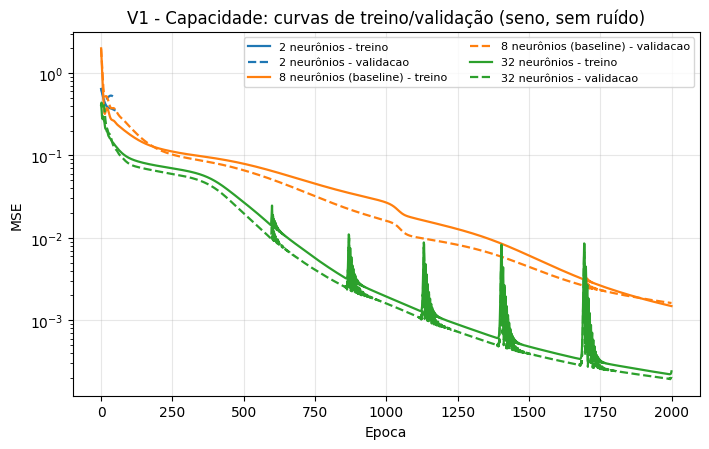

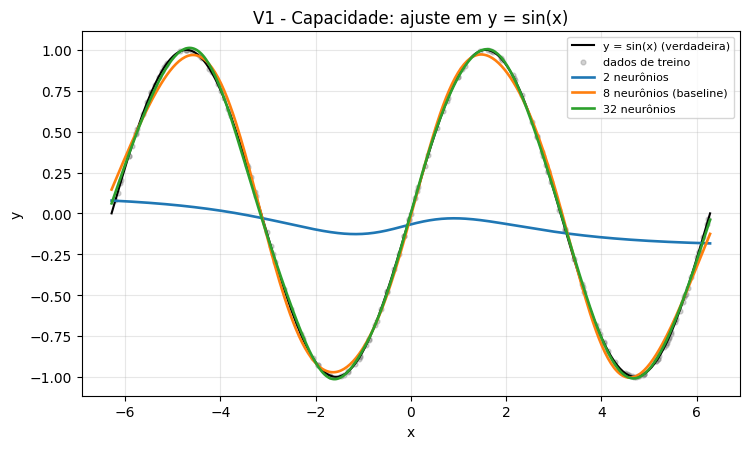

In [ ]:
v1_models = run_group(
    "V1_capacidade", BASELINE,
    {"2 neurônios": {"hidden_layer_sizes": (2,)},
     "8 neurônios (baseline)": {"hidden_layer_sizes": (8,)},
     "32 neurônios": {"hidden_layer_sizes": (32,)}},
    Xtr_s, ytr_clean, Xval_s, yval_clean, Xte_s, yte_clean,
)

plot_loss_curves({k: (tr, val) for k, (_, tr, val) in v1_models.items()},
                  "V1 - Capacidade: curvas de treino/validação (seno, sem ruído)",
                  save_name="v1_capacidade_curvas.png")
plot_sine_fits({k: m for k, (m, _, _) in v1_models.items()}, Xtr_s, ytr_clean,
               title="V1 - Capacidade: ajuste em y = sin(x)", save_name="v1_capacidade_ajuste.png")

### `V2: Ativação (seno, sem ruído): sigmoid x tanh x ReLU`

[20:42:23]   V2_ativacao | sigmoid: RMSE_val = 0.7054 +/- 0.0068
[20:42:39]   V2_ativacao | tanh (baseline): RMSE_val = 0.0551 +/- 0.0286
[20:42:51]   V2_ativacao | ReLU: RMSE_val = 0.2294 +/- 0.1109


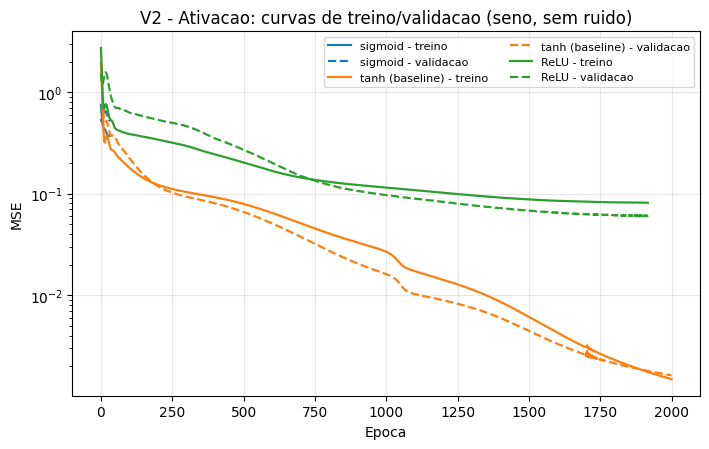

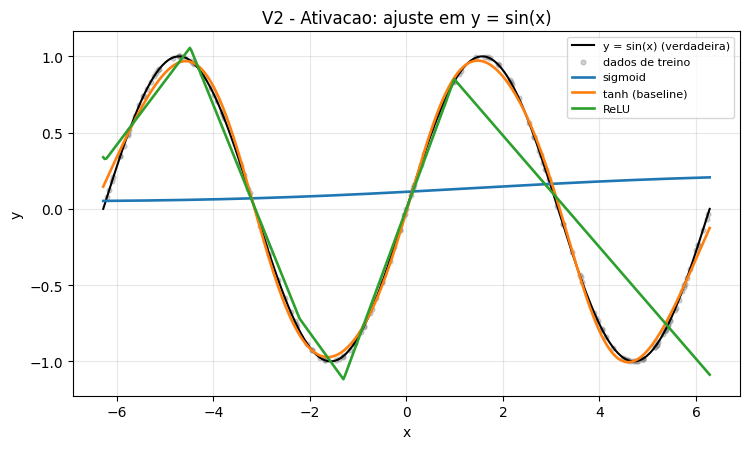

In [ ]:
v2_models = run_group(
    "V2_ativacao", BASELINE,
    {"sigmoid": {"activation": "logistic"},
     "tanh (baseline)": {"activation": "tanh"},
     "ReLU": {"activation": "relu"}},
    Xtr_s, ytr_clean, Xval_s, yval_clean, Xte_s, yte_clean,
)

plot_loss_curves({k: (tr, val) for k, (_, tr, val) in v2_models.items()},
                  "V2 - Ativacao: curvas de treino/validacao (seno, sem ruido)",
                  save_name="v2_ativacao_curvas.png")
plot_sine_fits({k: m for k, (m, _, _) in v2_models.items()}, Xtr_s, ytr_clean,
               title="V2 - Ativacao: ajuste em y = sin(x)", save_name="v2_ativacao_ajuste.png")

### `V3: Generalização/Ruído (seno, 8 neurônios): sem ruído x com ruído N(0, 0,1)`

**+ V3b (bônus)**: repete com 32 neurônios sob ruído, para testar se mais capacidade overfita mais.

[21:12:13] V3b (bonus) - RMSE contra a funcao VERDADEIRA, sob ruido:
[21:12:13]   8 neuronios sob ruido: 0.0726 +/- 0.0206
[21:12:13]   32 neuronios sob ruido: 0.0506 +/- 0.0054


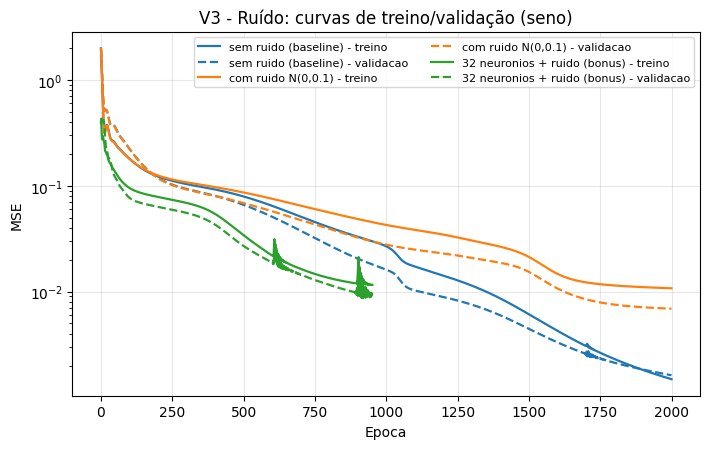

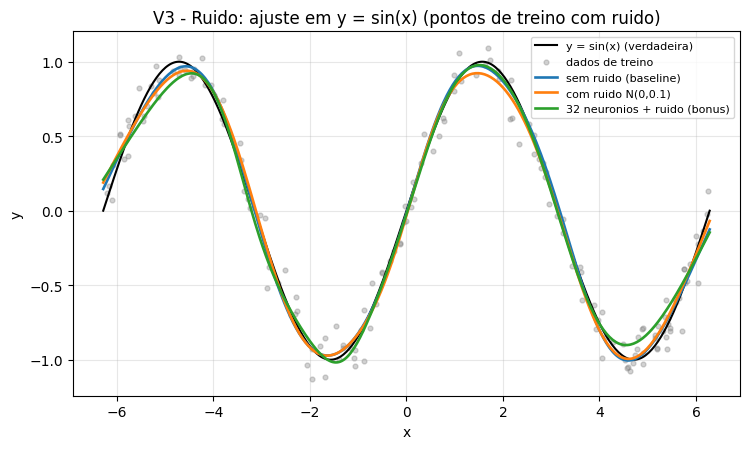

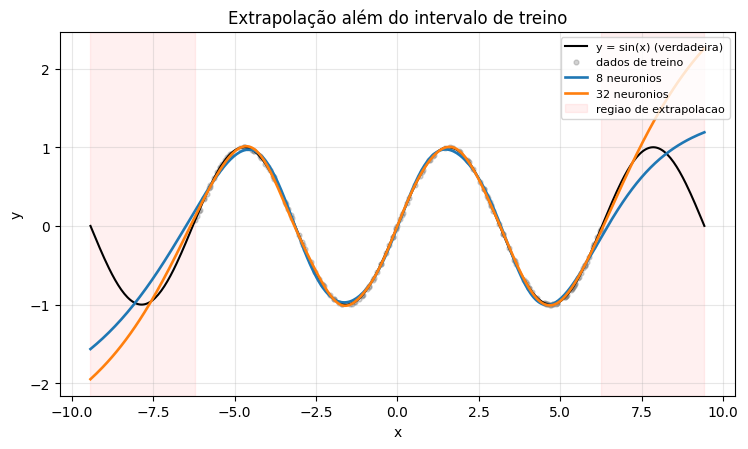

In [ ]:
v3_models = {}
for label, y_tr, y_val, y_te, y_true_val in [
    ("sem ruido (baseline)", ytr_clean, yval_clean, yte_clean, None),
    ("com ruido N(0,0.1)", ytr_noisy, yval_noisy, yte_noisy, yval_clean),
]:
    cfg = MLPConfig(**{**BASELINE.as_kwargs(), "noise_std": 0.0 if "sem" in label else NOISE_STD})
    cfg.name = f"V3_ruido::{label}"
    for seed in RANDOM_SEEDS:
        model, row, tr, val = run_one(cfg, Xtr_s, y_tr, Xval_s, y_val, Xte_s, y_te, seed, y_true_val=y_true_val)
        row["grupo"], row["rotulo"] = "V3_ruido", label
        ALL_RUNS.append(row)
        if seed == RANDOM_SEEDS[0]:
            v3_models[label] = (model, tr, val)

for seed in RANDOM_SEEDS:
    cfg = MLPConfig(**{**BASELINE.as_kwargs(), "hidden_layer_sizes": (32,), "noise_std": NOISE_STD})
    cfg.name = "V3b_bonus::32 neuronios + ruido"
    model, row, tr, val = run_one(cfg, Xtr_s, ytr_noisy, Xval_s, yval_noisy, Xte_s, yte_noisy, seed, y_true_val=yval_clean)
    row["grupo"], row["rotulo"] = "V3b_bonus", "32 neuronios + ruido"
    ALL_RUNS.append(row)
    if seed == RANDOM_SEEDS[0]:
        v3_models["32 neuronios + ruido (bonus)"] = (model, tr, val)

log("V3b (bonus) - RMSE contra a funcao VERDADEIRA, sob ruido:")
for grupo, label, tag in [("V3_ruido", "com ruido N(0,0.1)", "8 neuronios"),
                           ("V3b_bonus", "32 neuronios + ruido", "32 neuronios")]:
    vals = [r["RMSE_vs_funcao_verdadeira"] for r in ALL_RUNS if r["grupo"] == grupo and r["rotulo"] == label]
    log(f"  {tag} sob ruido: {np.mean(vals):.4f} +/- {np.std(vals):.4f}")

plot_loss_curves({k: (tr, val) for k, (_, tr, val) in v3_models.items()},
                  "V3 - Ruído: curvas de treino/validação (seno)", save_name="v3_ruido_curvas.png")
plot_sine_fits({k: m for k, (m, _, _) in v3_models.items()}, Xtr_s, ytr_noisy,
               title="V3 - Ruido: ajuste em y = sin(x) (pontos de treino com ruido)",
               save_name="v3_ruido_ajuste.png")

# extrapolacao alem do intervalo de treino (baseline vs 32 neuronios, sem ruido)
plot_sine_fits({"8 neuronios": v1_models["8 neurônios (baseline)"][0],
                "32 neuronios": v1_models["32 neurônios"][0]},
               Xtr_s, ytr_clean, extrap_range=(-3*np.pi, 3*np.pi),
               title="Extrapolação além do intervalo de treino", save_name="extrapolacao.png")

### `V4 — Escala (Concrete): atributos brutos x padronizados`

[20:59:52] V4_escala | bruto: RMSE_val = 16.759 +/- 0.331 MPa
[21:00:03] V4_escala | padronizado: RMSE_val = 6.897 +/- 0.308 MPa


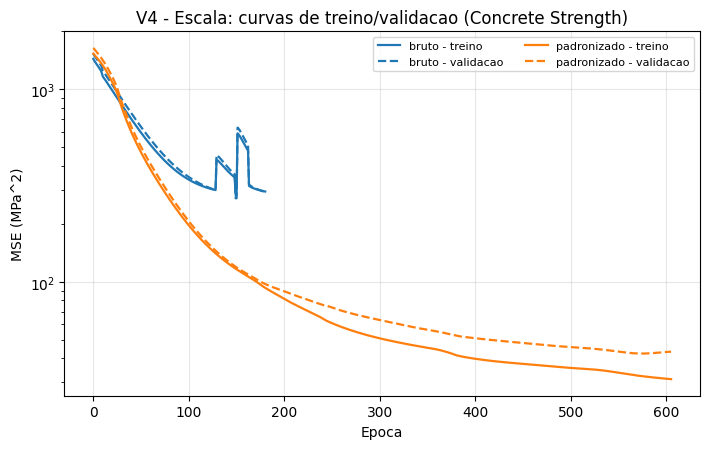

In [ ]:
v4_models = {}
for label, Xtr_v, Xval_v, Xte_v, std_flag in [
    ("bruto", Xtr_c_raw, Xval_c_raw, Xte_c_raw, False),
    ("padronizado", Xtr_c_std, Xval_c_std, Xte_c_std, True),
]:
    cfg = MLPConfig(**{**BASELINE_CONCRETO.as_kwargs(), "standardize_X": std_flag})
    cfg.name = f"V4_escala::{label}"
    for seed in RANDOM_SEEDS:
        model, row, tr, val = run_one(cfg, Xtr_v, ytr_c, Xval_v, yval_c, Xte_v, yte_c, seed)
        row["grupo"], row["rotulo"] = "V4_escala", label
        ALL_RUNS.append(row)
        if seed == RANDOM_SEEDS[0]:
            v4_models[label] = (model, tr, val)
    rmses = [r["RMSE_val"] for r in ALL_RUNS if r["grupo"] == "V4_escala" and r["rotulo"] == label]
    log(f"V4_escala | {label}: RMSE_val = {np.mean(rmses):.3f} +/- {np.std(rmses):.3f} MPa")

plot_loss_curves({k: (tr, val) for k, (_, tr, val) in v4_models.items()},
                  "V4 - Escala: curvas de treino/validacao (Concrete Strength)",
                  ylabel="MSE (MPa^2)", save_name="v4_escala_curvas.png")

### `Extensões opcionais`

Capacidade também no Concrete (EXT-A) e taxa de aprendizado no seno (EXT-B).

[21:15:47] EXT-A - Capacidade no Concreto (2 x 8 x 32, dados padronizados)...
[21:16:11]   EXT-A | 2 neuronios: RMSE_val = 7.242 +/- 0.383 MPa
[21:16:19]   EXT-A | 8 neuronios: RMSE_val = 6.897 +/- 0.308 MPa
[21:16:33]   EXT-A | 32 neuronios: RMSE_val = 5.602 +/- 0.302 MPa


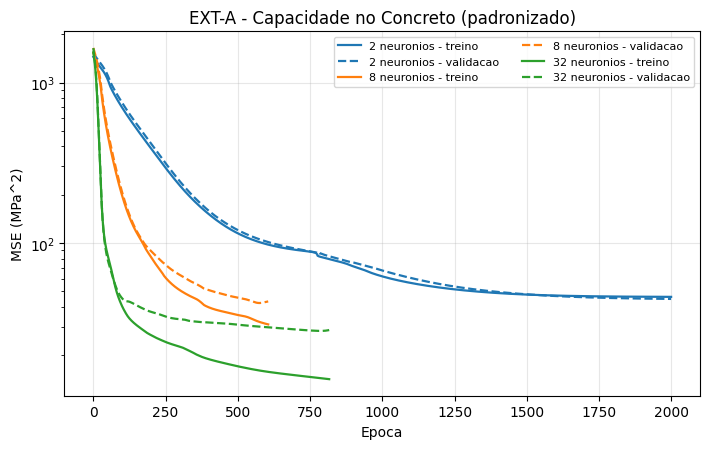

[21:16:34] EXT-B - Taxa de aprendizado (seno)...
[21:16:39]   EXT-B | lr=0.1: RMSE_val = 0.0684 +/- 0.0552
[21:16:55]   EXT-B | lr=0.01: RMSE_val = 0.0551 +/- 0.0286
[21:17:20]   EXT-B | lr=0.001: RMSE_val = 0.2776 +/- 0.0183


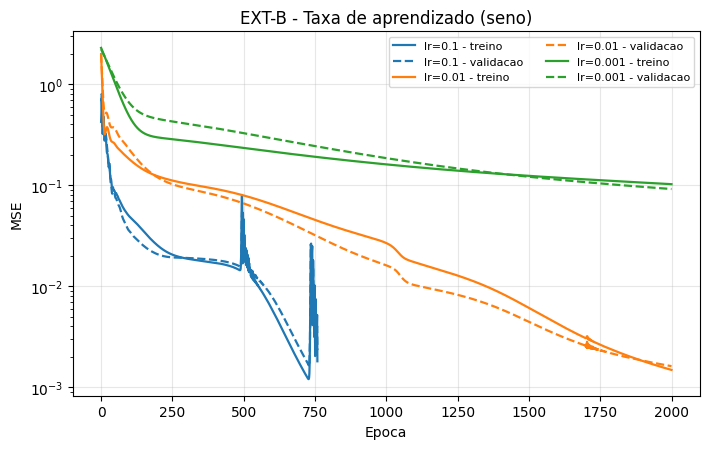

In [ ]:
RUN_EXTENSIONS = True

if RUN_EXTENSIONS:
    log("EXT-A - Capacidade no Concreto (2 x 8 x 32, dados padronizados)...")
    extA_models = {}
    for label, hidden in [("2 neuronios", (2,)), ("8 neuronios", (8,)), ("32 neuronios", (32,))]:
        cfg = MLPConfig(**{**BASELINE_CONCRETO.as_kwargs(), "hidden_layer_sizes": hidden, "standardize_X": True})
        cfg.name = f"EXT_A::{label}"
        for seed in RANDOM_SEEDS:
            model, row, tr, val = run_one(cfg, Xtr_c_std, ytr_c, Xval_c_std, yval_c, Xte_c_std, yte_c, seed)
            row["grupo"], row["rotulo"] = "EXT_A_capacidade_concreto", label
            ALL_RUNS.append(row)
            if seed == RANDOM_SEEDS[0]:
                extA_models[label] = (model, tr, val)
        rmses = [r["RMSE_val"] for r in ALL_RUNS if r["grupo"] == "EXT_A_capacidade_concreto" and r["rotulo"] == label]
        log(f"  EXT-A | {label}: RMSE_val = {np.mean(rmses):.3f} +/- {np.std(rmses):.3f} MPa")
    plot_loss_curves({k: (tr, val) for k, (_, tr, val) in extA_models.items()},
                      "EXT-A - Capacidade no Concreto (padronizado)", ylabel="MSE (MPa^2)",
                      save_name="extA_capacidade_concreto_curvas.png")

    log("EXT-B - Taxa de aprendizado (seno)...")
    extB_models = {}
    for lr in [0.1, 0.01, 0.001]:
        label = f"lr={lr}"
        cfg = MLPConfig(**{**BASELINE.as_kwargs(), "learning_rate_init": lr})
        cfg.name = f"EXT_B::{label}"
        for seed in RANDOM_SEEDS:
            model, row, tr, val = run_one(cfg, Xtr_s, ytr_clean, Xval_s, yval_clean, Xte_s, yte_clean, seed)
            row["grupo"], row["rotulo"] = "EXT_B_taxa", label
            ALL_RUNS.append(row)
            if seed == RANDOM_SEEDS[0]:
                extB_models[label] = (model, tr, val)
        rmses = [r["RMSE_val"] for r in ALL_RUNS if r["grupo"] == "EXT_B_taxa" and r["rotulo"] == label]
        log(f"  EXT-B | {label}: RMSE_val = {np.mean(rmses):.4f} +/- {np.std(rmses):.4f}")
    plot_loss_curves({k: (tr, val) for k, (_, tr, val) in extB_models.items()},
                      "EXT-B - Taxa de aprendizado (seno)", save_name="extB_taxa_aprendizado_curvas.png")
else:
    log("RUN_EXTENSIONS=False -> pulando EXT-A e EXT-B.")

### `Tabelas finais e variabilidade entre sementes`

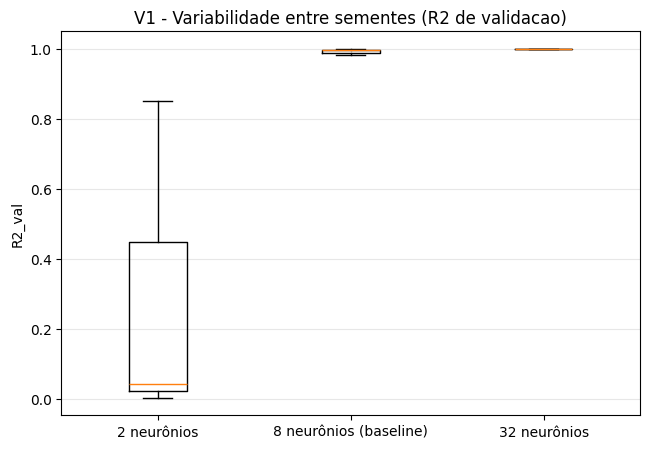

[21:24:29] Concluido. 36 execucoes registradas. Tabelas e figuras em 'outputs/'.


,grupo,rotulo,RMSE_val_media,RMSE_val_desvio,MAE_val_media,R2_val_media,epocas_media
0,EXT_A_capacidade_concreto,2 neuronios,7.242171,0.469468,5.708131,0.802370,2000.000000
1,EXT_A_capacidade_concreto,32 neuronios,5.601707,0.370226,4.293948,0.881749,606.333333
2,EXT_A_capacidade_concreto,8 neuronios,6.897143,0.376885,5.089277,0.820897,540.666667
3,EXT_B_taxa,lr=0.001,0.277604,0.022366,0.229034,0.841721,2000.000000
4,EXT_B_taxa,lr=0.01,0.055128,0.035015,0.041829,0.992114,2000.000000
5,EXT_B_taxa,lr=0.1,0.068430,0.067565,0.041443,0.984200,678.666667
6,V1_capacidade,2 neurônios,0.550999,0.243487,0.484342,0.298309,704.666667
7,V1_capacidade,32 neurônios,0.013504,0.002609,0.008657,0.999618,1741.666667
8,V1_capacidade,8 neurônios (baseline),0.055128,0.035015,0.041829,0.992114,2000.000000
9,V3_ruido,"com ruido N(0,0.1)",0.097214,0.018602,0.075397,0.979531,1830.666667


In [ ]:
df_all = pd.DataFrame(ALL_RUNS)
df_all.to_csv(OUTPUT_DIR / "tabela_configuracoes_completa.csv", index=False)

resumo = (df_all.groupby(["grupo", "rotulo"])
          .agg(RMSE_val_media=("RMSE_val", "mean"), RMSE_val_desvio=("RMSE_val", "std"),
               MAE_val_media=("MAE_val", "mean"), R2_val_media=("R2_val", "mean"),
               epocas_media=("n_epocas_rodadas", "mean"))
          .reset_index())
resumo.to_csv(OUTPUT_DIR / "tabela_resumo_por_config.csv", index=False)

plot_metric_by_group(df_all[df_all["grupo"] == "V1_capacidade"], "rotulo", "R2_val",
                      "V1 - Variabilidade entre sementes (R2 de validacao)",
                      save_name="v1_variabilidade_boxplot.png")
plot_metric_by_group(df_all[df_all["grupo"] == "V2_ativacao"], "rotulo", "RMSE_val",
                      "V2 - Variabilidade entre sementes (RMSE de validacao)",
                      save_name="v2_variabilidade_boxplot.png")

log(f"Concluido. {len(df_all)} execucoes registradas. Tabelas e figuras em '{OUTPUT_DIR}/'.")
resumo